# Visium HD mouse small intestine: a 2D segmentation-free cell-type map

This tutorial runs the SSAF-T pipeline in **2D** on a Visium HD section of mouse small intestine. Visium HD
measures counts in 2 µm bins, so the vector field is a blur of the binned counts rather than a KDE of
single molecules:

1. load the Space Ranger output into SpatialData
2. choose the gene panel: highly variable genes plus the Cell-Ontology markers for the organ
3. compute the vector field
4. downsample: sample anchor positions from the H&E tissue mask and look up their vectors
5. cluster the anchors
6. annotate the clusters with CeLLMan (`annotate-mode`, run outside the notebook)
7. map and filter cell types
8. cut the map into single cells, seeded by the ENACT nuclei

> Nuclei: Kamel, M. et al. *ENACT: End-to-End Analysis of Visium High Definition (HD) Data.* Bioinformatics 41(3),
> btaf094 (2025). https://doi.org/10.1093/bioinformatics/btaf094

## Data

10x Genomics dataset
[Visium HD Spatial Gene Expression Library, Mouse Small Intestine (FFPE)](https://www.10xgenomics.com/datasets/visium-hd-cytassist-gene-expression-libraries-of-mouse-intestine)
(CC BY 4.0). From the dataset page, download into `data/visiumhd_small_intestine/`:

- **Binned outputs (all bin levels)**, `Visium_HD_Mouse_Small_Intestine_binned_outputs.tar.gz`, then extract it
  (`tar xzf ...`) to get `binned_outputs/square_002um/`
- **Microscope image**, `Visium_HD_Mouse_Small_Intestine_tissue_image.btf` (full-resolution H&E)

The segmentation step uses the nuclei that [ENACT](https://github.com/Sanofi-Public/enact-pipeline) segments on this
H&E image with StarDist. Run ENACT on the same two inputs with the analysis name `mouse_small_intestine` and put its
output directory at `data/enact_output/`, so that `data/enact_output/mouse_small_intestine/nuclei_df.csv` exists.

Everything the notebook writes goes to `outputs/visiumhd_small_intestine/`. A CUDA GPU is required.

The gene panel and the annotation read the Cell-Ontology knowledge graph from its public server.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import ssaft

DATA    = Path("data/visiumhd_small_intestine")
FULLRES = DATA / "Visium_HD_Mouse_Small_Intestine_tissue_image.btf"
ENACT   = Path("data/enact_output/mouse_small_intestine")
OUT     = Path("outputs/visiumhd_small_intestine")
ZARR    = OUT / "ssaft_sdata.zarr"                 # SpatialData store: the input and every ssaft output
STORE   = OUT / "ssaft_store"                      # SSAF-T zarr store: vector field, anchors, maps
CLS     = OUT / "mouse_small_intestine_cls.h5ad"   # clustered anchors, the input of annotate-mode
ANNOTATION = OUT / "annotation_out"                # written by annotate-mode

SPECIES, ORGAN = "mouse", "small_intestine"        # Cell-Ontology module
ONTO_API = "https://cellman.pnucolab.com"          # public Cell-Ontology server

BIN_UM        = 2      # Visium HD native bin (um) -- also the vector-field lattice, see below
BANDWIDTH_UM  = 2.5    # kernel bandwidth of the vector field (um)
KERNEL        = "gaussian"   # KDE kernel; stated rather than left to the default
SAMPLING_DIST = 2.0    # asked-for lattice spacing (um); on a bin raster it cannot go below BIN_UM
HVG_N         = 5000

DS = "visiumhd_small_intestine"

DEVICE = "cuda"
NCORES = 30
OUT.mkdir(parents=True, exist_ok=True)

## 1. Load Visium HD

`load_visiumhd` reads the 2 µm bins and the full-resolution H&E with `spatialdata_io.visium_hd` and keeps the
in-tissue bins. It converts bin coordinates to µm and fits the bin-lattice-to-pixel affine. The result is a
SpatialData with the counts in `tables['table']` and the H&E in `images['staining']`.

In [2]:
import spatialdata as sd
import spatialdata_plot

sdata = ssaft.load_visiumhd(DATA, species=SPECIES, organ=ORGAN, bin_um=BIN_UM, fullres_image_file=str(FULLRES))
sdata.write(ZARR)
grid = ssaft.GridDataset.from_sdata(sdata)

for kind in ("images", "tables"):
    print(f"{kind:7s}", list(getattr(sdata, kind).keys()))
print(sdata.tables["table"])

images  ['staining']
tables  ['table']
AnnData object with n_obs × n_vars = 5479660 × 19059
    obs: 'in_tissue', 'array_row', 'array_col', 'location_id', 'region', 'pxl_col_in_fullres', 'pxl_row_in_fullres'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatialdata_attrs', 'cellman'
    obsm: 'spatial'


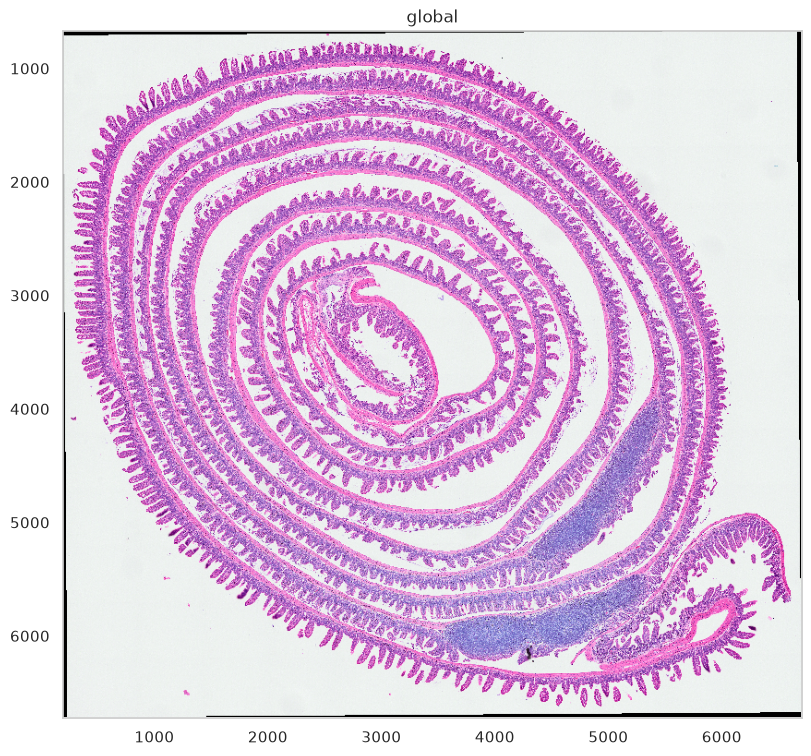

In [3]:
sdata.pl.render_images("staining").pl.show(figsize=(8, 8))

## 2. Gene panel

The field is built on highly variable genes plus every marker the Cell-Ontology lists for the organ. Low-variance
marker genes stay in, so the annotation can still see them.

In [4]:
panel, onto_markers = ssaft.select_gene_panel(grid.raw, SPECIES, ORGAN, hvg_n=HVG_N, server_url=ONTO_API)
print("panel genes:", len(panel), "| ontology markers in the panel:", len(onto_markers))

[panel] HVG (seurat_v3 on 100000 bins, denylist-filtered): 4996
[panel] slim-index mouse/small_intestine: n_terms=80 version=2026-09-14 → 344 marker genes
[panel] final panel: 5202 genes (HVG 4996 ∪ ontology-in-data 333)
panel genes: 5202 | ontology markers in the panel: 333


## 3. Vector field

`compute_vf` rasterises the bin counts on a `BIN_UM` grid and blurs every gene with a kernel of `BANDWIDTH_UM`.
`bandwidth_um` is the kernel's standard deviation. Each
voxel is normalised and log-transformed, and the result is stored in the store as `vf_normalized`, with its norm
`vf_norm`. The stored grid is decimated from the raster by `round(sampling_distance / bin_um)`, so it can be coarser
than the bins but never finer: with 2 µm bins the field stays at 2 µm whatever `SAMPLING_DIST` asks for
(`round(1.0 / 2) = 0` decimation is clamped to a stride of 1), which is why it is set to `BIN_UM` here.

In [ ]:
ds = ssaft.Dataset(str(STORE))
analysis = ssaft.Analysis(ds, ncores=NCORES, verbose=True)

analysis.compute_vf(sdata, bin_um=BIN_UM, panel=panel, sampling_distance=SAMPLING_DIST,
                    bandwidth_um=BANDWIDTH_UM, kernel=KERNEL, device=DEVICE)

## 4. Downsampling

`z=2`: one tissue mask from the H&E image in `sdata.images`, inverted before Otsu because H&E is dark tissue on a
bright background. Anchors are sampled per `block_um` block and their vectors are looked up in the stored field.
`vf_norm_percentile` drops anchors in the lowest-density quarter.

In [ ]:
adata = analysis.downsample_vector(sdata, z=2, n_samples_per_block=5, block_um=10, vf_norm_percentile=25)
adata

In [ ]:
ds.plot_downsampled_vector(s=0.01)
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.title(f"{adata.n_obs:,} anchors")
plt.show()

## 5. Clustering

In [ ]:
import rapids_singlecell as rsc

# The anchors x panel matrix is ~13 GB dense, so the vector field's GPU allocation has to be freed
# first (restart the kernel after the downsampling) or pca has to be given chunked=True
rsc.pp.pca(adata, n_comps=50)
rsc.pp.neighbors(adata, n_neighbors=15)
rsc.tl.leiden(adata, resolution=1)
print(adata.obs["leiden"].nunique(), "clusters")
adata.write_h5ad(CLS)

## 6. Agentic annotation (outside the notebook)

Clusters are named by CeLLMan's **annotate-mode** skill, which runs in Claude Code or Codex rather than in this
kernel (see the README for installing the skill and the `annotate-expert` agent). Start it with a prompt like this,
filling in the absolute paths:

```
/annotate-mode Annotate the h5ad below using the annotate-expert agent.

- input          : <SSAF-T>/notebooks/outputs/visiumhd_small_intestine/mouse_small_intestine_cls.h5ad
- tissue         : mouse, small intestine
- cluster column : leiden
- virtual env    : <path to the Python environment with ssaft installed>
- out            : <SSAF-T>/notebooks/outputs/visiumhd_small_intestine/annotation_out
```

It writes `mouse_small_intestine_cls_annotated.h5ad` with `obs['cellman_annotation']`, the rationale for every
cluster, and `celltype_markers.yaml`, which the mapping uses below.

In [ ]:
import scanpy as sc

ANNO    = ANNOTATION / "mouse_small_intestine_cls_annotated.h5ad"
MARKERS = ANNOTATION / "celltype_markers.yaml"

anno = sc.read_h5ad(ANNO)
print(anno.obs["cellman_annotation"].value_counts().to_string())

In [ ]:
fig, ax = plt.subplots(figsize=(9, 9))
sc.pl.embedding(anno, basis="spatial", color="cellman_annotation", size=1, ax=ax, show=False, frameon=False,
                title="annotated anchors")
ax.set_aspect("equal")
ax.invert_yaxis()
plt.show()

## 7. Cell-type mapping and filtering

The store holds `vf_normalized`, so `map_celltypes` reads the field instead of computing a KDE. It scores every voxel
against the annotated anchors (`method='lda'`), using each cell type's KG markers from `celltype_markers.yaml`.
`filter_celltypemaps` with its defaults then cuts each cell type at 0.3 of its own density peak.

In [ ]:
sdata = analysis.map_celltypes(sdata, method="lda", kernel=KERNEL, h5ad=str(ANNO), marker_genes_path=str(MARKERS),
                               gpu_device=DEVICE)
sdata = analysis.filter_celltypemaps(sdata)

## Colours

Colour is a presentation choice, but SSAF-T stores it once so every view agrees — the RGB map image, the cells
table and any plot built from them. The palette used in the paper was matched by cell-type name against the
reference annotation, so that the SSAF-T panel and the published panel of the same section share one legend; it
is **not** what the pipeline picks by default. It ships next to this notebook.

`set_celltype_palette` rewrites the store attribute, the annotated table's `uns['cellman_annotation_colors']`
and re-renders the RGB image, so it has to run before anything is drawn.

In [ ]:
import json

PALETTE = json.load(open(f"palettes/{DS}_celltype_colors.json"))["colors"]
names, _ = ds.celltype_names_colors()
missing = [n for n in names if n not in PALETTE]
assert not missing, f"no colour for {missing}"       # a label with no colour would silently fall back

analysis.set_celltype_palette(sdata, colors=[PALETTE[n] for n in names])
names, colors = ds.celltype_names_colors()
print(f"{len(colors)} curated colours applied")

In [ ]:
from matplotlib.colors import Normalize
from matplotlib.patches import Patch

names, colors = ds.celltype_names_colors()
fig, ax = plt.subplots(figsize=(9, 10), dpi=200)
sdata.pl.render_images("ssaft_celltype_map_rgb", norm=Normalize(vmin=0, vmax=255)).pl.show(ax=ax)
ax.get_images()[0].set_interpolation("nearest")
ax.legend(handles=[Patch(facecolor=c, label=n) for n, c in zip(names, colors)],
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
ax.set_title("filtered cell-type map")
plt.show()

## 8. Nuclei and segmentation

`segment_cells` needs nuclei as watershed seeds and uses their centroids. They come from ENACT's StarDist segmentation
of the H&E (`nuclei_df.csv`, one WKT polygon per nucleus).

ENACT crops the image to the bounding box of the in-tissue bins before segmenting, so its coordinates are in that
crop's pixel frame. Adding the crop origin puts them back on the full-resolution image. They then take the H&E
image's transformation, which places them in the same µm coordinate system as the map. Without the origin shift the
nuclei land about 40 µm away from their H&E position.

In [ ]:
import pandas as pd
import geopandas as gpd
from shapely import from_wkt
from spatialdata.models import ShapesModel
from spatialdata.transformations import get_transformation

tp = pd.read_parquet(DATA / "binned_outputs/square_002um/spatial/tissue_positions.parquet")
tp = tp[tp.in_tissue == 1].astype({"pxl_col_in_fullres": int, "pxl_row_in_fullres": int})
tp = tp[(tp.pxl_col_in_fullres >= 0) & (tp.pxl_row_in_fullres >= 0)]
x_min, y_min = int(tp.pxl_col_in_fullres.min()), int(tp.pxl_row_in_fullres.min())

df = pd.read_csv(ENACT / "nuclei_df.csv", usecols=["geometry", "id"])
nuclei = gpd.GeoDataFrame(
    geometry=gpd.GeoSeries(from_wkt(df["geometry"].to_numpy())).translate(x_min, y_min).to_numpy(),
    index=pd.Index(df["id"].to_numpy(), name="nucleus_id"))

sdata.shapes["enact_nucleus_boundaries"] = ShapesModel.parse(
    nuclei, transformations=dict(get_transformation(sdata.images["staining"], get_all=True)))
print(f"{len(nuclei):,} ENACT nuclei; crop origin (px) x={x_min}, y={y_min}")

In [ ]:
# a 150 um window of the H&E with the ENACT nucleus outlines
import json
mpp = json.loads((DATA / "binned_outputs/square_002um/spatial/scalefactors_json.json").read_text())["microns_per_pixel"]
w = int(150 / mpp)
x0, y0 = int(tp.pxl_col_in_fullres.median()), int(tp.pxl_row_in_fullres.median())
img = sdata.images["staining"]
if not hasattr(img, "dims"):                   # multiscale: take the full-resolution level
    img = img[list(img.children)[0]]["image"]
he = np.moveaxis(np.asarray(img[:, y0:y0 + w, x0:x0 + w]), 0, -1)

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(he, extent=(x0, x0 + w, y0 + w, y0))
inwin = nuclei.cx[x0:x0 + w, y0:y0 + w]
inwin.boundary.plot(ax=ax, color="#00e5ff", linewidth=0.6)
ax.set_xlim(x0, x0 + w)
ax.set_ylim(y0 + w, y0)
ax.set_title(f"ENACT nuclei, {len(inwin):,} in a 150 um window")
ax.axis("off")
plt.show()

In [ ]:
sdata = analysis.segment_cells(sdata, nuclei="enact_nucleus_boundaries")
cells = sdata.tables["ssaft_cells"]
print(cells)
print(cells.obs["cellman_annotation"].value_counts().to_string())

In [ ]:
lut = dict(zip(names, colors))
g = sdata.shapes["ssaft_cell_boundaries_2d"]
lab = cells.obs["cellman_annotation"].astype(str).to_numpy()

fig, ax = plt.subplots(figsize=(11, 12), dpi=200)
g.plot(ax=ax, color=[lut[c] for c in lab], linewidth=0)
ax.set_aspect("equal")
ax.invert_yaxis()
ax.set_xticks([])
ax.set_yticks([])
ax.legend(handles=[Patch(facecolor=lut[c], label=c) for c in sorted(set(lab))],
          loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, fontsize=8)
plt.show()

In [ ]:
# One store holds everything that is kept. SSAF-T adds its elements to the SpatialData in memory;
# this writes the ones the zarr does not have yet -- the cell-type map, the cell boundaries and the
# cells table, plus the ENACT nuclei, which were added after the first write.
SKIP = {"ssaft_downsampled_vectors"}     # the anchors stay in the SSAF-T store, not here
on_disk = set(sdata.elements_paths_on_disk())
new = sorted({p.rsplit("/", 1)[-1] for p in sdata.elements_paths_in_memory()
              if p not in on_disk} - SKIP)
sdata.write_element(new)                 # spatialdata cannot overwrite an element inside its own
print("written:", new)                   # store: delete_element_from_disk first to replace one

saved = sd.read_zarr(ZARR)
for kind in ("images", "labels", "points", "shapes", "tables"):
    print(f"{kind:7s}", list(getattr(saved, kind).keys()))